<img src="https://uwe-cyber.github.io/images/uwe_banner.png">

# UFCFEL-15-3 Security Data Analytics and Visualisation
## Portfolio Assignment: Part 1
### Academic year: 2025-26

## Conduct a security investigation on web traffic from an organisation
---

For this task, the company UWEtech have enlisted your support as a security data analyst. They believe that they have suffered an attack on their network, however they are unable to diagnose what has happened exactly. The company have provided you with an extract of their network traffic, for which you will use visualisation techniques to learn more about the underlying activity on their systems.

**Dataset:** You will be issued a dataset for this task via GitLab: https://gitlab.uwe.ac.uk/a23-mccarthy/sdav-2025

**This exercise carries a weight of 25% towards your overall portfolio submission**

It is strongly encouraged that you use the online reference guides for [Matplotlib](https://matplotlib.org/) and [pandas](https://pandas.pydata.org/) - searching the API documentation will answer many of your questions.


### Submission Documents
---

For Part 1 of your portfolio, your complete output file should be saved as:

- **STUDENT_ID-PART1.ipynb**

This should then be included in a ZIP file along with your other two portfolio documents.

The deadline for all portfolio submissions is **THURSDAY 11th DECEMBER @ 14:00**. 

In [3]:
### Load in the libraries and the data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

def load_csv_data():
    data = pd.read_csv('./part1/packet-capture3.csv')
    return data

data = load_csv_data()
data = data[ data['Source'].isin(data['Source'].value_counts().head(30).index) ] 
data = data.drop('No.', axis=1)
data


,Time,Source,Destination,Protocol,Length,Info
0,0.000000,10.20.0.165,209.85.143.19,TCP,62,1698 > 443 [SYN] Seq=0 Win=65535 Len=0 MSS=1...
1,0.017691,209.85.143.19,10.20.0.165,TCP,62,"443 > 1698 [SYN, ACK] Seq=0 Ack=1 Win=5720 L..."
2,0.017729,10.20.0.165,209.85.143.19,TCP,54,1698 > 443 [ACK] Seq=1 Ack=1 Win=65535 Len=0
3,0.018382,10.20.0.165,209.85.143.19,SSLv3,156,Client Hello
4,0.032859,209.85.143.19,10.20.0.165,TCP,60,443 > 1698 [ACK] Seq=1 Ack=103 Win=5720 Len=0
...,...,...,...,...,...,...
9380,833.452154,10.20.0.165,10.20.0.130,SMB,180,"Tree Connect AndX Request, Path: \\\\WIN-JIDID..."
9382,833.458302,10.20.0.165,10.20.0.130,SMB,130,"Trans2 Request, GET_DFS_REFERRAL, File:"
9384,833.557382,10.20.0.165,10.20.0.130,SMB,156,"Trans2 Request, GET_DFS_REFERRAL, File: \\bhra..."
9386,833.558091,10.20.0.165,10.20.0.130,SMB,148,"Trans2 Request, GET_DFS_REFERRAL, File: \\BHRA..."


---


### Question 1: Plot a Line Chart that clearly depicts "Seconds" on the x-axis, and "Total Number of Packets" sent on the y-axis, complete with axis labeling. 

#### (4 marks)

*Hint: The time is given in seconds with millisecond precision - think how you could aggregate this value to represent seconds only, then research a function that counts the value totals in your data.*

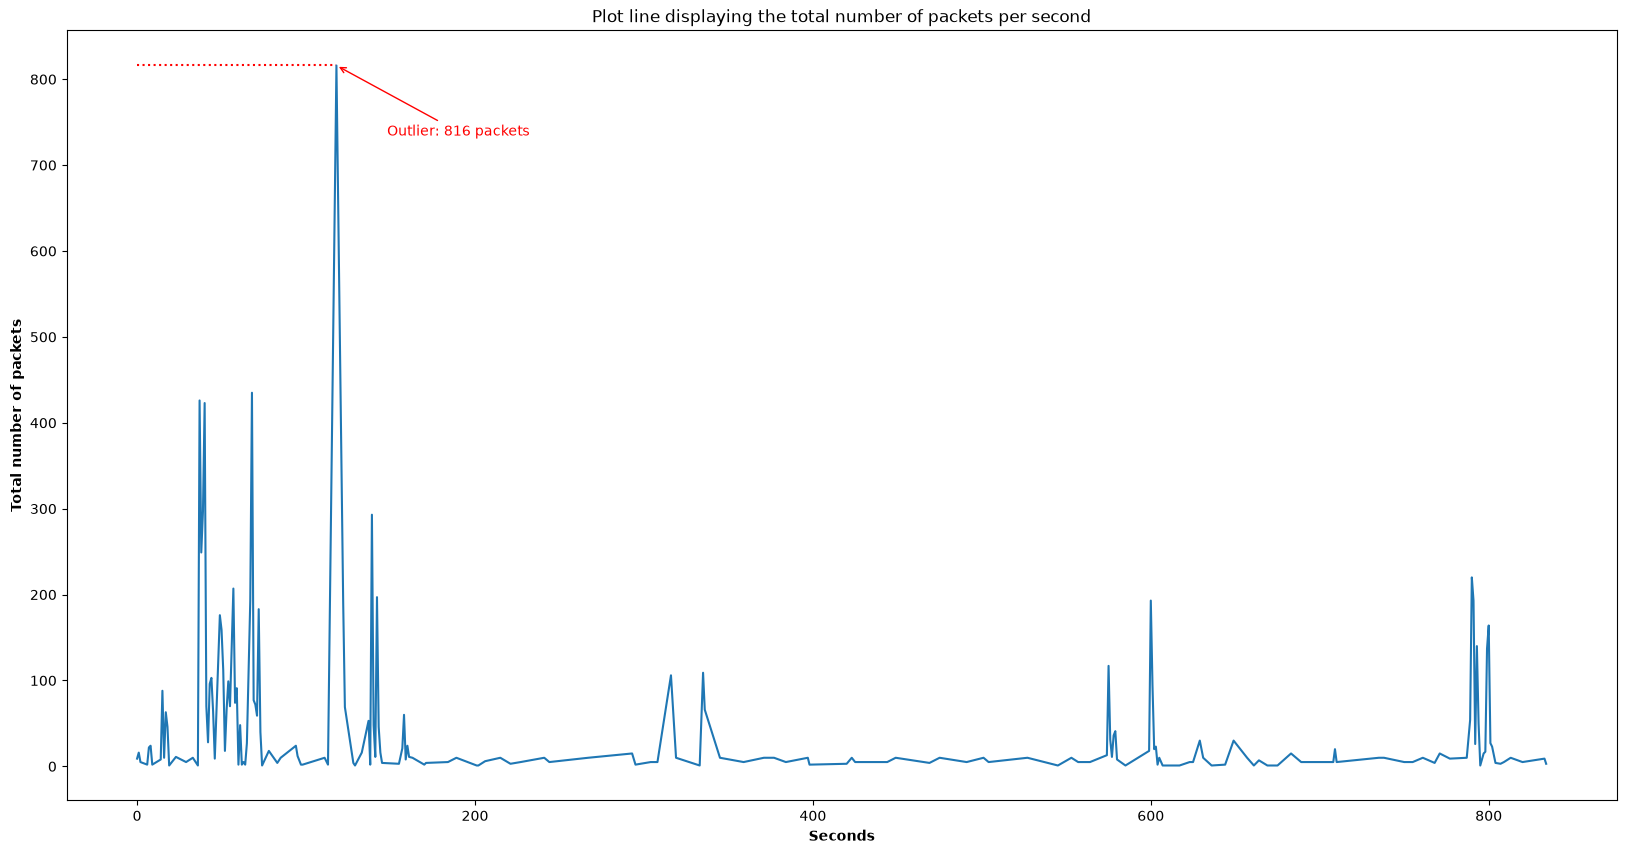

In [4]:
plt.figure(figsize=(20,10))
# The first step is to convert the time to remove the millisecond precision 
# For that I chose to round the values using pandas round() method then converted the Time data type  from float to int 
data['Time'].describe()
data['Time']=data['Time'].round()
data['Time'] =data['Time'].astype('int64') 
# Using the value_counts function to get the total number of packets per second in our dataset 

#Ordering the Packets_Num in order they appear in the Dataframe 
Packets_Num= data.Time.value_counts()[data.Time.unique()]
#As it was required to generate a plot line chart the kind of the plot function was set as line 
Packets_Num.plot(kind='line')

# Mark the highest packet count with a dotted guide and an arrow.
outlier_time = Packets_Num.idxmax()
outlier_count = Packets_Num.max()
plt.hlines(outlier_count, xmin=Packets_Num.index.min(), xmax=outlier_time,
           colors='red', linestyles='dotted')
plt.annotate(f'Outlier: {outlier_count} packets',
             xy=(outlier_time, outlier_count),
             xytext=(outlier_time + 30, outlier_count * 0.9),
             color='red',
             arrowprops=dict(arrowstyle='->', color='red'))
plt.title('Plot line displaying the total number of packets per second')
plt.xlabel('Seconds', fontweight='bold')
plt.ylabel('Total number of packets', fontweight='bold')


plt.show()

### Question 2: Display a Bar Chart that shows "Protocol" on the x-axis, and "Count" on the y-axis, complete with axis labeling. 
#### (2 marks)

*Hint: Search the pandas documentation for creating a Bar Chart from a DataFrame column.*

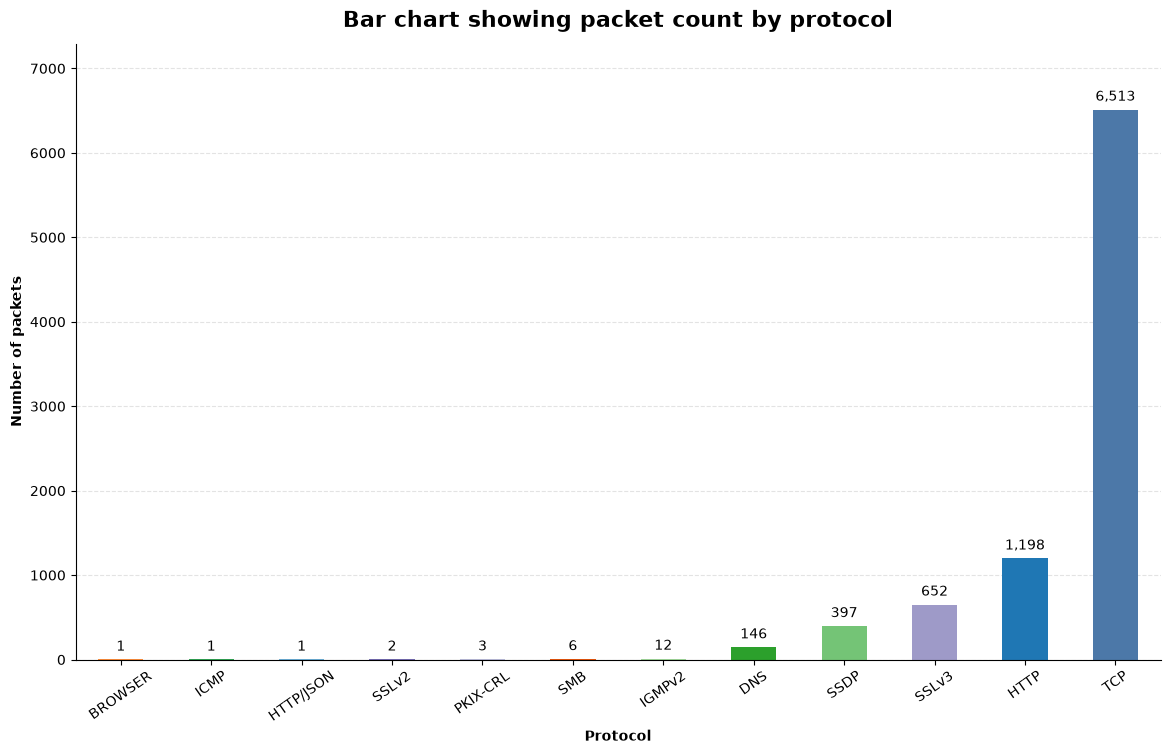

In [5]:
plt.figure(figsize=(14, 8))
# Count each protocol and sort from least to most common for a clear horizontal chart.
Protocol_count = pd.Series.value_counts(data['Protocol']).sort_values(ascending=True)

# Related protocols share a colour family; shades help distinguish protocols within each family.
protocol_colors = {
    'TCP': '#4C78A8',
    'HTTP': '#1F77B4', 'HTTP/JSON': '#6BAED6',
    'SSLv2': '#756BB1', 'SSLv3': '#9E9AC8', 'PKIX-CRL': '#BCBDDC',
    'DNS': '#2CA02C', 'SSDP': '#74C476', 'IGMPv2': '#A1D99B', 'ICMP': '#31A354',
    'SMB': '#E6550D', 'BROWSER': '#FD8D3C'
}

ax = Protocol_count.plot(
    kind='bar',
    color=[protocol_colors.get(protocol, '#808080') for protocol in Protocol_count.index]
)
ax.set_title('Bar chart showing packet count by protocol', fontsize=16, fontweight='bold', pad=12)
ax.set_ylabel('Number of packets', fontweight='bold')
ax.set_xlabel('Protocol', fontweight='bold')
ax.tick_params(axis='x', labelrotation=35)
ax.grid(axis='y', linestyle='--', alpha=0.35)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_ylim(0, Protocol_count.max() * 1.12)

# Add values at the end of each bar so small bars are easier to compare.
for bar in ax.patches:
    value = int(bar.get_height())
    ax.annotate(f'{value:,}',
                (bar.get_x() + bar.get_width() / 2, value),
                xytext=(0, 4), textcoords='offset points',
                ha='center', va='bottom', fontsize=10)
plt.show()

### Question 3: Display a Scatter Chart that shows the association between Source and Destination data. 

#### (2 marks)
*Hint: Matplotlib has a scatterplot function that takes x and y as inputs*

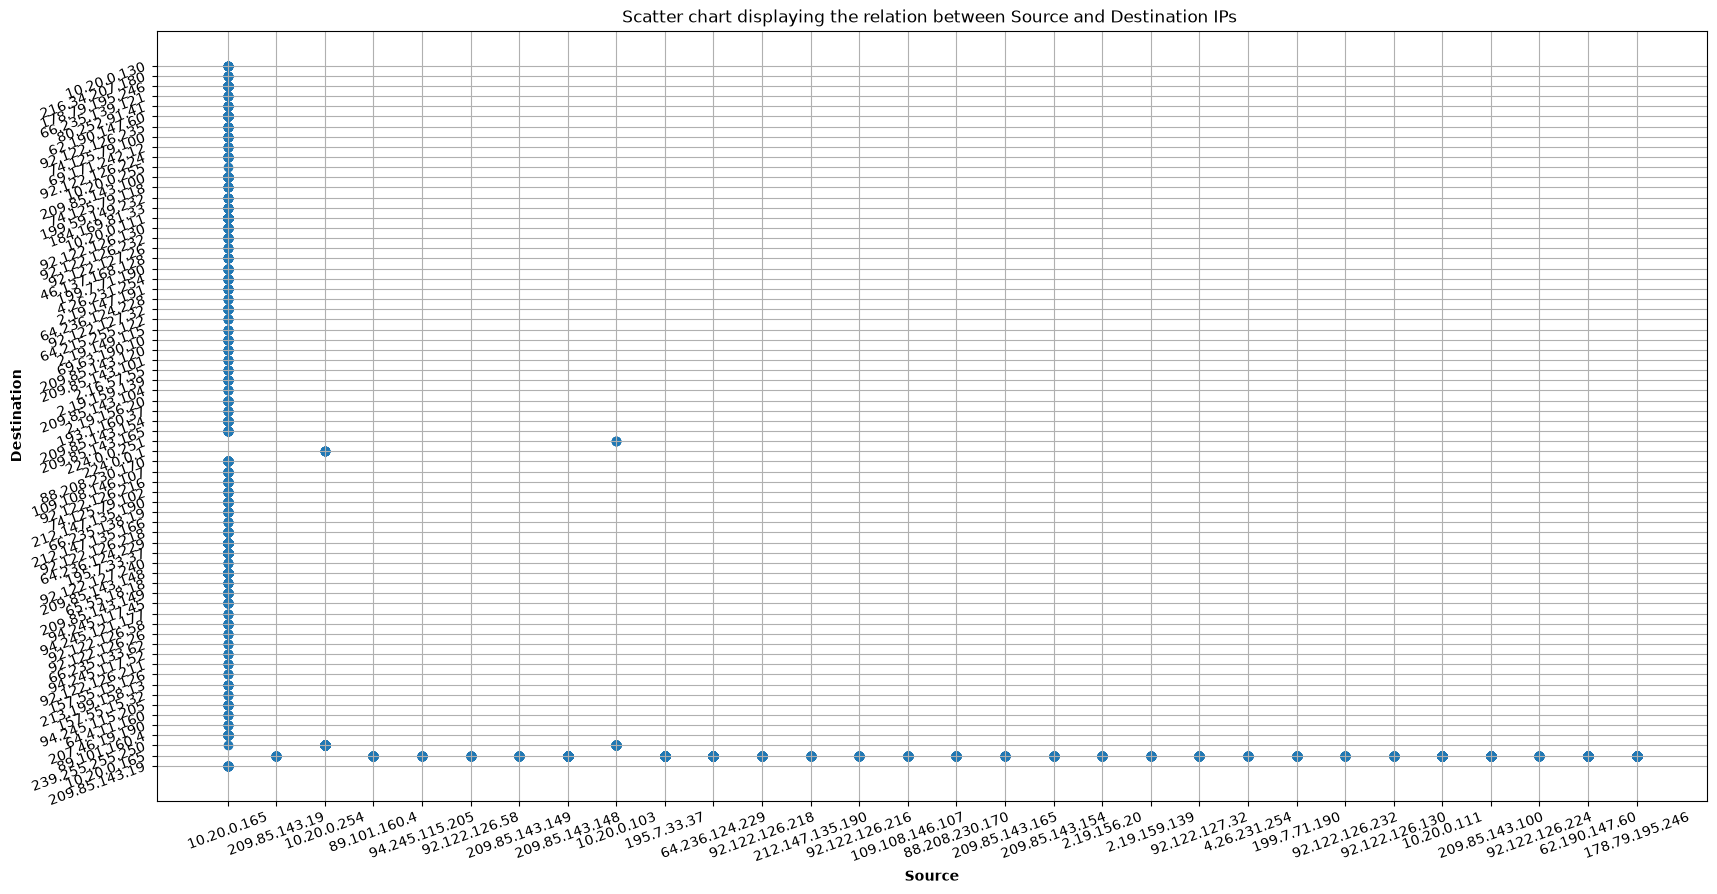

In [6]:
plt.figure(figsize=(20,10))
plt.xticks(rotation=20)
plt.yticks(rotation=20)
# Using the  matplotlib scatter function I was able to create a scatter chart which has Destination as Y and Source as X 
plt.scatter(data['Source'],data['Destination'])
plt.title('Scatter chart displaying the relation between Source and Destination IPs ')
plt.xlabel('Source', fontweight='bold')
plt.ylabel('Destination', fontweight='bold')
plt.grid()
plt.show()

### Question 4: Display the data as a node link diagram using Source and Destination as your edges. 

#### (3 marks)

*Hint: Look at the NetworkX library: https://networkx.org/ and the online course notes.*

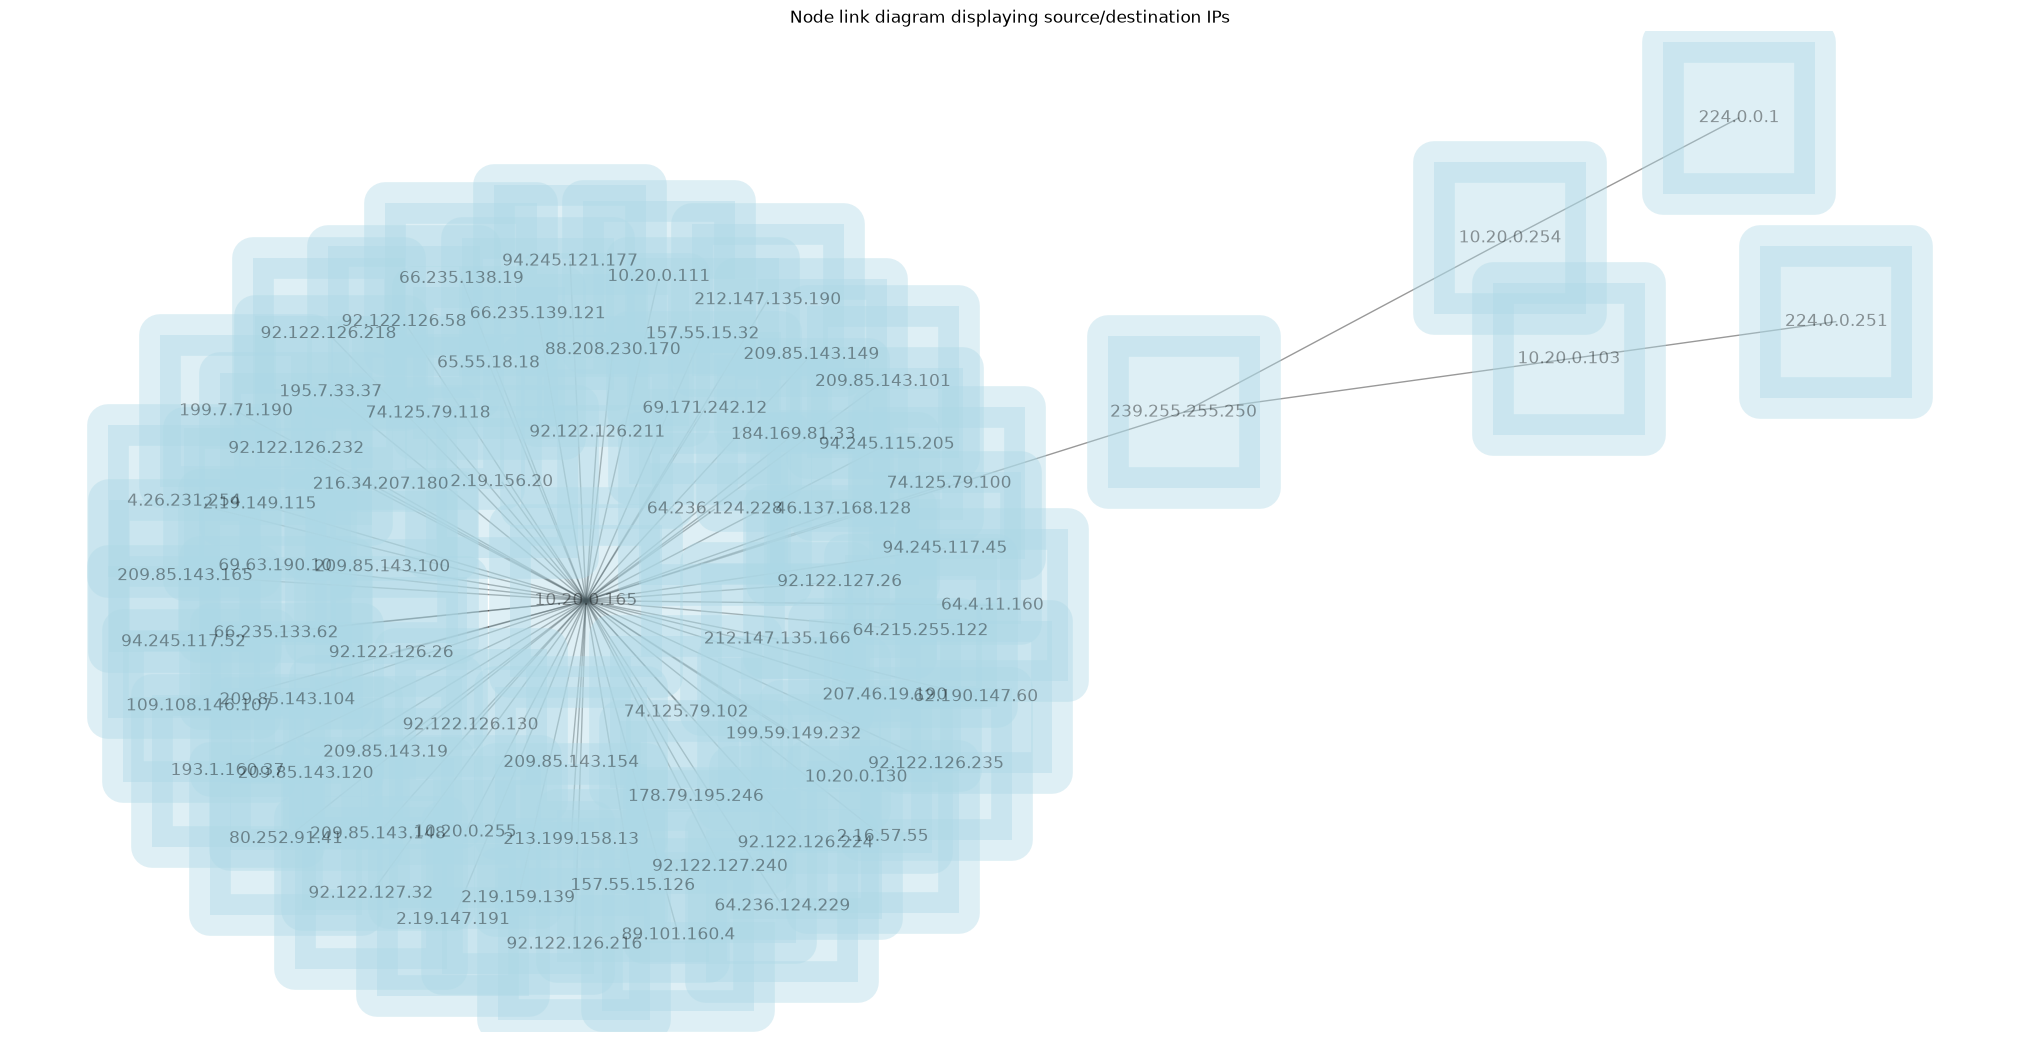

In [7]:
plt.figure(figsize=(20,10))
# Using the networkx library I was able to create a node link diagram which displays the relation between Source and Destination IPs
G = nx.from_pandas_edgelist(data, source='Source', target='Destination', edge_attr=None)
pos = nx.spring_layout(G) 
# Drawing the nodes and edges after tweaking the node size and linewidths to get a better graph 
nx.draw(G,with_labels=True,node_size=12000,node_color="lightblue",node_shape='s',alpha=0.4,linewidths=30)
plt.title('Node link diagram displaying source/destination IPs')

plt.show()

### Question 5: For each Protocol type, create a new Column and assign whether the Protocol usage is True or False 

#### (2 marks)
Hint: Get a list of unique protocol values, assign each value to be a new column where the Protocol column is equal to the Protocol name.

In [8]:
# Display the unique protocol values in the dataset.
data.Protocol.unique()

# Create one Boolean column for each protocol value.
# Each row is True for the column matching its protocol, and False for the others.
new_columns = pd.get_dummies(data['Protocol'], dtype=bool)

# Add the new protocol columns to the original DataFrame.
new_data = pd.concat([data, new_columns], axis=1)

new_data

,Time,Source,Destination,Protocol,Length,Info,BROWSER,DNS,HTTP,HTTP/JSON,ICMP,IGMPv2,PKIX-CRL,SMB,SSDP,SSLv2,SSLv3,TCP
0,0,10.20.0.165,209.85.143.19,TCP,62,1698 > 443 [SYN] Seq=0 Win=65535 Len=0 MSS=1...,False,False,False,False,False,False,False,False,False,False,False,True
1,0,209.85.143.19,10.20.0.165,TCP,62,"443 > 1698 [SYN, ACK] Seq=0 Ack=1 Win=5720 L...",False,False,False,False,False,False,False,False,False,False,False,True
2,0,10.20.0.165,209.85.143.19,TCP,54,1698 > 443 [ACK] Seq=1 Ack=1 Win=65535 Len=0,False,False,False,False,False,False,False,False,False,False,False,True
3,0,10.20.0.165,209.85.143.19,SSLv3,156,Client Hello,False,False,False,False,False,False,False,False,False,False,True,False
4,0,209.85.143.19,10.20.0.165,TCP,60,443 > 1698 [ACK] Seq=1 Ack=103 Win=5720 Len=0,False,False,False,False,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9380,833,10.20.0.165,10.20.0.130,SMB,180,"Tree Connect AndX Request, Path: \\\\WIN-JIDID...",False,False,False,False,False,False,False,True,False,False,False,False
9382,833,10.20.0.165,10.20.0.130,SMB,130,"Trans2 Request, GET_DFS_REFERRAL, File:",False,False,False,False,False,False,False,True,False,False,False,False
9384,834,10.20.0.165,10.20.0.130,SMB,156,"Trans2 Request, GET_DFS_REFERRAL, File: \\bhra...",False,False,False,False,False,False,False,True,False,False,False,False
9386,834,10.20.0.165,10.20.0.130,SMB,148,"Trans2 Request, GET_DFS_REFERRAL, File: \\BHRA...",False,False,False,False,False,False,False,True,False,False,False,False


### Question 6: Show a Multi-Line Chart that shows the Total Number of Packets Per Protocol on the y-axis and "Seconds" on the x-axis. You should display a legend that states the colour of each protocol.

#### (6 marks)
*Hint: Think about how you did this in Question 1 , and recall that plt.plot can be used to append to an existing plot.*

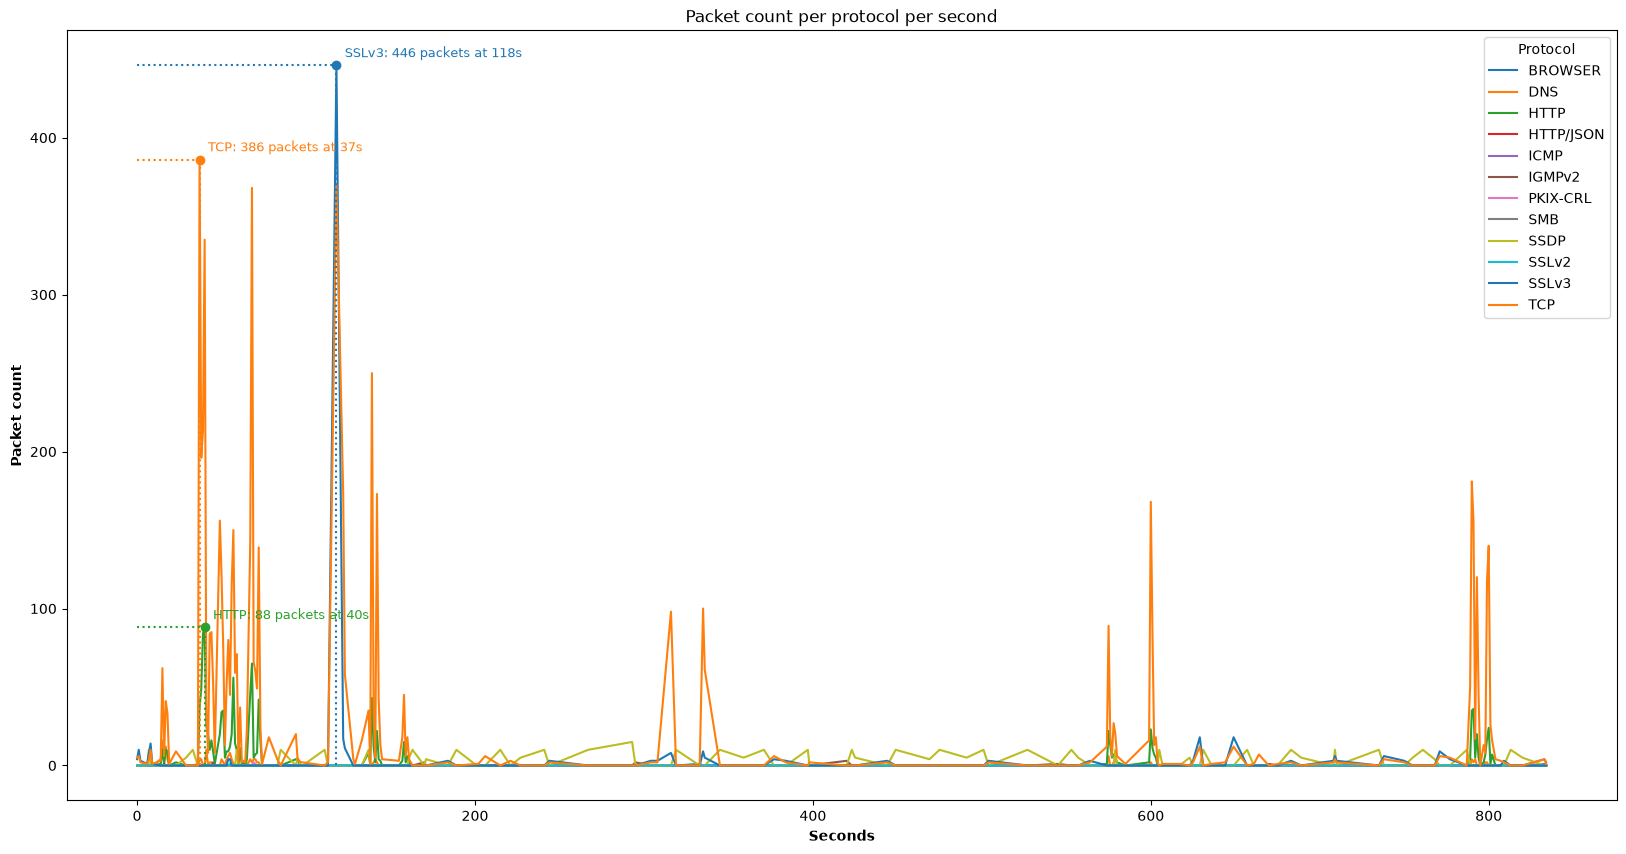

In [9]:
# Round timestamps to whole seconds so packets are grouped into one-second intervals.
data = data.assign(Seconds=data['Time'].round().astype(int))

# Count packets for each protocol in each second.
packet_counts = data.groupby(['Seconds', 'Protocol']).size()

# Reshape the counts so seconds are rows and each protocol has its own column.
pivot_df = packet_counts.unstack('Protocol', fill_value=0)

# Plot one line for every protocol, with a legend identifying each line.
ax = pivot_df.plot(figsize=(20, 10))

# Mark the peak of each of the three protocols with the largest peaks.
tall_protocols = pivot_df.max().nlargest(3).index
for protocol in tall_protocols:
    peak_time = pivot_df[protocol].idxmax()
    peak_count = pivot_df.loc[peak_time, protocol]
    color = ax.lines[pivot_df.columns.get_loc(protocol)].get_color()
    ax.hlines(peak_count, xmin=pivot_df.index.min(), xmax=peak_time,
              colors=color, linestyles='dotted', linewidth=1.5)
    ax.vlines(peak_time, ymin=0, ymax=peak_count,
              colors=color, linestyles='dotted', linewidth=1.5)
    ax.scatter(peak_time, peak_count, color=color, zorder=5)
    ax.annotate(f'{protocol}: {peak_count} packets at {peak_time}s',
                xy=(peak_time, peak_count), xytext=(6, 6),
                textcoords='offset points', color=color, fontsize=9)
plt.title('Packet count per protocol per second')
plt.xlabel('Seconds', fontweight='bold')
plt.ylabel('Packet count', fontweight='bold')
plt.legend(title='Protocol')
plt.show()

### Question 7: Describe what you believe are the key findings of each plot, including discussion of any stand-out features. Give justification for your answer in the context of a security scenario. Limit your response to a maximum of 200 words.

#### (6 marks)

Q1 – Packet activity over time: Traffic peaks at 818 packets around 116 seconds. A sudden burst could come from a normal busy period or unusual automated activity, so compare it with the network’s usual pattern.

Q2 – Protocol counts: TCP is most common, followed by HTTP and SSLv3. SSLv3 is outdated and may expose traffic to weaker encryption, so check which systems use it and whether it is still needed.

Q3 – Source/destination scatter plot: Many connections involve 10.20.0.165, especially with 195.7.33.37 and 10.20.0.111. A busy host could be a server, but unexpected connections might indicate misuse; check the host’s role and whether these peers are trusted.

Q4 – Node-link diagram: It also highlights connections around 10.20.0.165, which may help identify a central host or unusual relationships. However, the crowded, undirected graph hides who initiated each connection, so it cannot confirm suspicious activity by itself.

Q5 – Protocol indicator table: The 12 Boolean columns show which protocol each packet uses. This makes older SSL traffic easier to identify and check against security policy.

Q6 – Packet counts by protocol over time: SSLv3 peaks around 118 seconds, alongside the overall traffic peak. Check which hosts and sessions caused the spike; packet volume alone does not prove an attack.